# Исследование рынка стартапов
Наместникова Софья
## Введение

Финансовая компания планирует выйти на инвестиционный рынок и рассматривает покупку, развитие и последующую перепродажу перспективных стартапов. Для выбора направления необходимо изучить, как менялись объёмы и типы финансирования, какие рыночные сегменты росли к 2014 году и какая доля предоставленных средств возвращалась инвесторам.

Исследование выполняется с позиции начала 2015 года. Данные за 2014 год будут отдельно проверены на полноту, поэтому выводы по последнему году интерпретируются осторожно.

### Цель и задачи

**Цель:** определить перспективный рыночный сегмент и подходящий тип финансирования для инвестиционной стратегии заказчика.

**Задачи:**

1. Загрузить и предобработать данные о компаниях, финансировании и возвратах.
2. Разделить компании по длительности финансирования.
3. Выделить массовые, средние и нишевые сегменты рынка.
4. Найти аномальные объёмы финансирования методом IQR внутри каждого сегмента.
5. Определить период, за который данных достаточно для анализа.
6. Сравнить типы финансирования по объёму, популярности и возвратам.
7. Изучить годовую динамику раундов, типичного размера раунда, растущих массовых сегментов и нормированной доли возвратов.
8. Сформулировать рекомендацию для заказчика на 2015 год.

### Описание данных

Основной датасет `cb_investments` содержит сведения о компаниях:

- название, сайт, рыночный сегмент, статус и географию;
- количество раундов и участников;
- даты основания, первого, среднего и последнего финансирования;
- общий объём финансирования `funding_total_usd`;
- объёмы по отдельным типам финансирования: `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Дополнительный датасет `cb_returns` содержит годовые объёмы возвращённых средств по тем же типам финансирования за 2000–2014 годы. Значения возвратов указаны в миллионах долларов.

---

## Шаг 1. Знакомство с данными: загрузка и предобработка

### 1.1 Загрузка и общая информация

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

INVESTMENTS_URL = 'https://code.s3.yandex.net/datasets/cb_investments.zip'
RETURNS_URL = 'https://code.s3.yandex.net/datasets/cb_returns.csv'

try:
    investments = pd.read_csv(
        '/datasets/cb_investments.zip', sep=';', low_memory=False
    )
    returns = pd.read_csv('/datasets/cb_returns.csv')
except FileNotFoundError:
    investments = pd.read_csv(
        INVESTMENTS_URL, sep=';', low_memory=False
    )
    returns = pd.read_csv(RETURNS_URL)

initial_rows = len(investments)
print(f'cb_investments: {investments.shape[0]:,} строк, {investments.shape[1]} столбцов')
print(f'cb_returns: {returns.shape[0]} строк, {returns.shape[1]} столбцов')

cb_investments: 54,294 строк, 40 столбцов
cb_returns: 15 строк, 14 столбцов


Сначала посмотрю первые строки и типы данных обеих таблиц. Это позволит определить проблемы, которые нужно устранить перед анализом.

In [2]:
investments.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.00,NaN,1636-09-08,NaN,NaN,"1,636.00",2014-01-06,NaN,2014-01-06,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"90,000,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.00,NaN,1785-01-01,NaN,NaN,"1,785.00",2014-05-15,NaN,2014-05-15,0.00,"2,000,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.00,1.00,1802-07-19,NaN,NaN,"1,802.00",2009-07-02,2009-07-02,2009-07-02,0.00,"9,000,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,3.00,0.00,1817-01-01,NaN,NaN,"1,817.00",2013-11-21,2013-11-21,2014-11-03,0.00,0.00,0.00,"1,600,000.00",0.00,0.00,0.00,"6,100,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,1.00,NaN,1826-01-01,NaN,NaN,"1,826.00",2014-01-14,NaN,2014-01-14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"540,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [3]:
investments.info()

<class 'pandas.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  str    
 1   homepage_url          45989 non-null  str    
 2   category_list         45477 non-null  str    
 3    market               45477 non-null  str    
 4    funding_total_usd    49438 non-null  str    
 5   status                48124 non-null  str    
 6   country_code          44165 non-null  str    
 7   state_code            30161 non-null  str    
 8   region                44165 non-null  str    
 9   city                  43322 non-null  str    
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  str    
 13  founded_month         38482 non-null  str    
 14  founded_quarter       38482 non-null  str    
 15  founded_year          38554 no

In [4]:
returns.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.00,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.00,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.00,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.00,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.00,2.19,3.38,0.00,0.55,0.00


In [5]:
returns.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


В таблице `cb_investments` 54 294 строки и 40 столбцов. Названия `market` и `funding_total_usd` содержат лишние пробелы. Общий объём финансирования записан как текст с разделителями разрядов, а даты — как `object`. В таблице много пропусков, в том числе в сегменте рынка и средней дате финансирования. Также необходимо проверить полностью пустые строки и дубликаты.

Таблица `cb_returns` содержит 15 наблюдений — по одному на каждый год с 2000 по 2014 — и 13 типов финансирования. Её числовые типы корректны; столбец `year` следует сделать индексом.

### 1.2 Предобработка данных

#### Названия столбцов

Приведу названия столбцов к `snake_case`: удалю пробелы по краям, переведу текст в нижний регистр и заменю последовательности пробелов подчёркиванием.

In [6]:
original_columns = investments.columns.tolist()
investments.columns = (
    investments.columns
      .str.strip()
      .str.lower()
      .str.replace(r'\s+', '_', regex=True)
)
returns.columns = (
    returns.columns
      .str.strip()
      .str.lower()
      .str.replace(r'\s+', '_', regex=True)
)

pd.DataFrame({
    'исходное название': original_columns,
    'новое название': investments.columns
}).head(10)

,исходное название,новое название
0,name,name
1,homepage_url,homepage_url
2,category_list,category_list
3,market,market
4,funding_total_usd,funding_total_usd
5,status,status
6,country_code,country_code
7,state_code,state_code
8,region,region
9,city,city


#### Полные дубликаты и строки без финансирования

Сначала удалю полные дубликаты. Затем преобразую `funding_total_usd` в число и удалю строки без общего объёма финансирования: они не позволяют решить основные задачи проекта. Полностью пустые строки также входят в эту группу.

In [7]:
empty_rows = investments.isna().all(axis=1).sum()
full_duplicates = investments.duplicated().sum()

print(f'Полностью пустых строк: {empty_rows:,}')
print(f'Полных дубликатов: {full_duplicates:,}')

investments = investments.drop_duplicates().copy()

investments['funding_total_usd'] = pd.to_numeric(
    investments['funding_total_usd']
      .astype('string')
      .str.replace(',', '', regex=False),
    errors='coerce'
)

missing_funding = investments['funding_total_usd'].isna().sum()
print(f'Строк без данных о финансировании после удаления дублей: {missing_funding:,}')

investments = investments.dropna(subset=['funding_total_usd']).copy()

Полностью пустых строк: 4,856
Полных дубликатов: 4,855
Строк без данных о финансировании после удаления дублей: 8,532


#### Даты и заполнение `mid_funding_at`

Преобразую четыре столбца с датами. Две строки содержат некорректные годы первого финансирования (`0011` и `0007`), которые невозможно надёжно восстановить. Поскольку дальнейший анализ строится по времени финансирования, эти две строки удалю и отдельно учту в доле отфильтрованных данных.

Пропуски в `mid_funding_at` заполню серединой интервала между первой и последней датами финансирования.

In [8]:
date_columns = [
    'founded_at', 'first_funding_at',
    'mid_funding_at', 'last_funding_at'
]

for column in date_columns:
    investments[column] = pd.to_datetime(
        investments[column], errors='coerce', format='mixed'
    )

invalid_core_dates = investments[
    ['first_funding_at', 'last_funding_at']
].isna().any(axis=1)

print('Строки с некорректной первой или последней датой:')
display(
    investments.loc[
        invalid_core_dates,
        ['name', 'funding_rounds', 'first_funding_at', 'last_funding_at']
    ]
)

investments = investments.loc[~invalid_core_dates].copy()

mid_missing_before = investments['mid_funding_at'].isna().sum()
mid_missing = investments['mid_funding_at'].isna()
investments.loc[mid_missing, 'mid_funding_at'] = (
    investments.loc[mid_missing, 'first_funding_at']
    + (
        investments.loc[mid_missing, 'last_funding_at']
        - investments.loc[mid_missing, 'first_funding_at']
    ) / 2
)

print(f'Пропусков mid_funding_at до заполнения: {mid_missing_before:,}')
print(f'Пропусков mid_funding_at после заполнения: '
      f'{investments["mid_funding_at"].isna().sum()}')

Строки с некорректной первой или последней датой:


,name,funding_rounds,first_funding_at,last_funding_at


Пропусков mid_funding_at до заполнения: 13,676
Пропусков mid_funding_at после заполнения: 0


#### Текстовые признаки и таблица возвратов

Для признаков, которые используются далее, заменю пропуски на `unknown`. Это позволит не потерять компании при группировках, но неизвестный рынок не будет считаться реальным массовым сегментом. В таблице возвратов сделаю год индексом.

In [9]:
text_columns = ['name', 'market', 'status', 'country_code']
text_missing_before = investments[text_columns].isna().sum()

for column in text_columns:
    investments[column] = (
        investments[column]
          .fillna('unknown')
          .astype(str)
          .str.strip()
    )

returns = returns.drop_duplicates().set_index('year').sort_index()
returns.index.name = 'year'

print('Заменённые пропуски в текстовых столбцах:')
display(text_missing_before.to_frame('количество'))
print(f'Дубликатов в cb_returns: {returns.duplicated().sum()}')
print(f'Период cb_returns: {returns.index.min()}–{returns.index.max()} годы')

Заменённые пропуски в текстовых столбцах:


,количество
name,1
market,2503
status,1105
country_code,3819


Дубликатов в cb_returns: 0
Период cb_returns: 2000–2014 годы


#### Оставшиеся пропуски и полнота данных

In [10]:
missing_after = pd.DataFrame({
    'missing_count': investments.isna().sum(),
    'missing_share_pct': (investments.isna().mean() * 100).round(2)
})
missing_after[missing_after['missing_count'] > 0].sort_values(
    'missing_share_pct', ascending=False
)

,missing_count,missing_share_pct
state_code,15288,37.37
participants,13576,33.19
founded_month,8772,21.44
founded_quarter,8772,21.44
founded_at,8706,21.28
founded_year,8706,21.28
city,4505,11.01
region,3819,9.34
category_list,2503,6.12
homepage_url,2314,5.66


In [11]:
removed_rows = initial_rows - len(investments)
print(f'Исходное число строк: {initial_rows:,}')
print(f'После предобработки: {len(investments):,}')
print(f'Удалено строк: {removed_rows:,} ({removed_rows / initial_rows:.2%})')
print(f'Сохранено данных: {len(investments) / initial_rows:.2%}')

Исходное число строк: 54,294
После предобработки: 40,907
Удалено строк: 13,387 (24.66%)
Сохранено данных: 75.34%


### Промежуточный вывод по шагу 1

Я привела названия столбцов к единому стилю, преобразовала общий объём финансирования в число, даты в `datetime`, а год в таблице возвратов сделала индексом. Удалено 4 855 полных дубликатов, 8 532 строки без данных о финансировании и две строки с невосстановимыми датами. Осталось 40 905 компаний 75,34% исходных данных.

Все 13 675 пропусков в `mid_funding_at` заполнены серединой между первой и последней датами. Пропуски сохраняются в необязательных описательных полях, но ключевые для анализа признаки — общий объём, число раундов и даты финансирования заполнены. Данных достаточно для решения задач проекта, однако 2 503 компании с неизвестным рынком будут учитываться отдельной технической группой `unknown`.

---

## Шаг 2. Инжиниринг признаков

### 2.1 Группы по срокам финансирования

Разделю компании на три группы. Если был один раунд, компания относится к единичному финансированию. Для остальных рассчитаю интервал между первой и последней датами: до 365 дней включительно или более года.

In [12]:
funding_span_days = (
    investments['last_funding_at'] - investments['first_funding_at']
).dt.days

investments['funding_period_group'] = np.select(
    [
        investments['funding_rounds'].eq(1),
        investments['funding_rounds'].gt(1) & funding_span_days.le(365),
        investments['funding_rounds'].gt(1) & funding_span_days.gt(365)
    ],
    [
        'Единичное финансирование',
        'Срок финансирования до года',
        'Срок финансирования более года'
    ],
    default='Не определено'
)

duration_order = [
    'Единичное финансирование',
    'Срок финансирования до года',
    'Срок финансирования более года'
]

duration_stats = (
    investments.groupby('funding_period_group')
      .agg(
          companies=('name', 'size'),
          funding_usd=('funding_total_usd', 'sum')
      )
      .reindex(duration_order)
)
duration_stats['company_share_pct'] = (
    duration_stats['companies'] / duration_stats['companies'].sum() * 100
)
duration_stats['funding_share_pct'] = (
    duration_stats['funding_usd'] / duration_stats['funding_usd'].sum() * 100
)
duration_stats.round(2)

,companies,funding_usd,company_share_pct,funding_share_pct
funding_period_group,,,,
Единичное финансирование,24113,199304424483,58.95,30.62
Срок финансирования до года,4501,48885981057,11.00,7.51
Срок финансирования более года,12293,402743297604,30.05,61.87


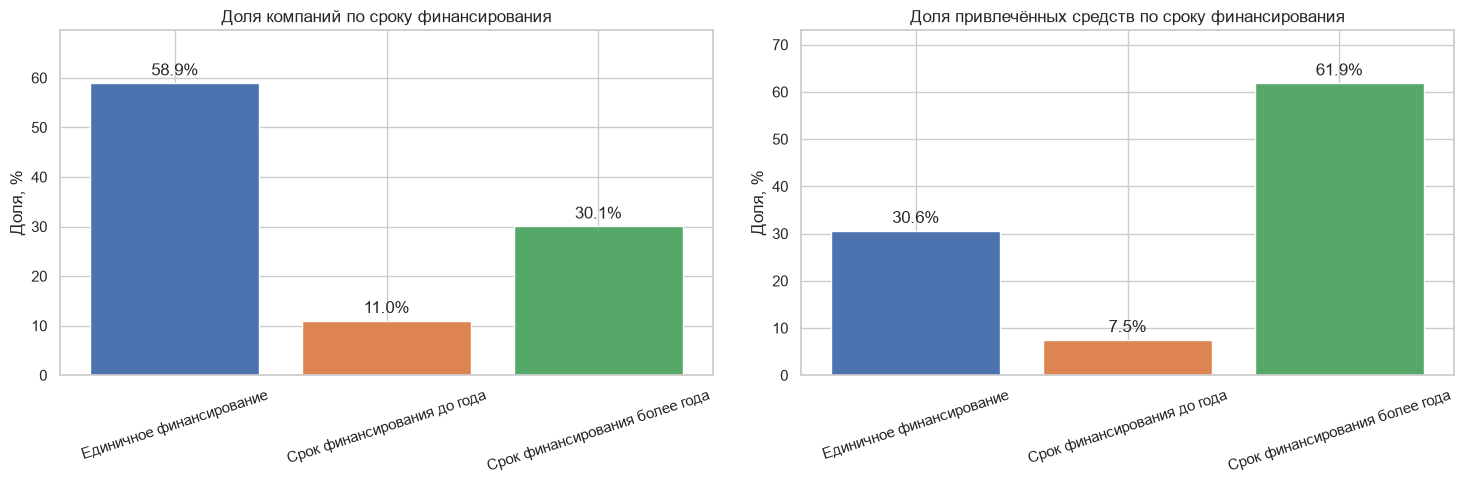

In [13]:
duration_palette = {
    'Единичное финансирование': '#4C72B0',
    'Срок финансирования до года': '#DD8452',
    'Срок финансирования более года': '#55A868'
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, column, title in [
    (axes[0], 'company_share_pct', 'Доля компаний по сроку финансирования'),
    (axes[1], 'funding_share_pct', 'Доля привлечённых средств по сроку финансирования')
]:
    values = duration_stats.loc[duration_order, column]
    bars = ax.bar(
        duration_order,
        values,
        color=[duration_palette[item] for item in duration_order]
    )
    ax.bar_label(bars, fmt='%.1f%%', padding=3)
    ax.set_title(title)
    ax.set_ylabel('Доля, %')
    ax.tick_params(axis='x', rotation=18)
    ax.set_ylim(0, max(values) * 1.18)

plt.tight_layout()
plt.show()

Единичным раундом ограничились 24 113 компанийоколо 59% выборки, но они получили только 30,6% общего финансирования. Компании со сроком привлечения более года составляют около 30%, однако аккумулируют 61,9% средств. Продолжительное финансирование связано с заметно большим объёмом привлечённого капитала.

### 2.2 Массовые, средние и нишевые сегменты

Сегменты с числом компаний более 120 считаю массовыми, от 35 до 120 включительно средними, менее 35 нишевыми. Пропуски `market` остаются отдельной группой `unknown` и не участвуют в классификации реальных рынков.

In [14]:
market_counts = (
    investments.loc[investments['market'].ne('unknown'), 'market']
      .value_counts()
)

market_class = pd.cut(
    market_counts,
    bins=[-np.inf, 34, 120, np.inf],
    labels=['niche', 'mid', 'mass']
)

segment_summary = pd.DataFrame({
    'segments': market_class.value_counts(),
    'companies': (
        pd.DataFrame({'class': market_class, 'companies': market_counts})
          .groupby('class', observed=True)['companies']
          .sum()
    )
}).reindex(['mass', 'mid', 'niche'])

segment_summary

,segments,companies
mass,48,33733
mid,57,3841
niche,289,830


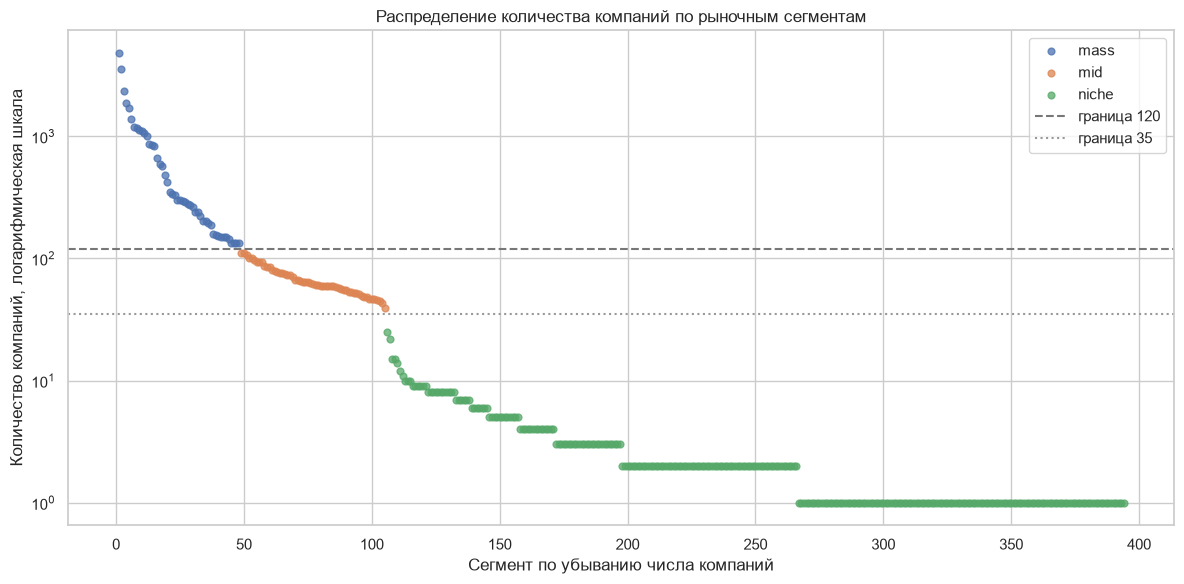

In [15]:
market_distribution = market_counts.sort_values(ascending=False).reset_index(drop=True)
market_distribution_class = market_distribution.map(
    lambda value: 'mass' if value > 120 else ('mid' if value >= 35 else 'niche')
)
segment_colors = {'mass': '#4C72B0', 'mid': '#DD8452', 'niche': '#55A868'}

plt.figure(figsize=(12, 6))
for segment_class in ['mass', 'mid', 'niche']:
    mask = market_distribution_class.eq(segment_class)
    plt.scatter(
        market_distribution.index[mask] + 1,
        market_distribution[mask],
        s=24,
        alpha=0.75,
        label=segment_class,
        color=segment_colors[segment_class]
    )

plt.axhline(120, color='#777777', linestyle='--', label='граница 120')
plt.axhline(35, color='#999999', linestyle=':', label='граница 35')
plt.yscale('log')
plt.title('Распределение количества компаний по рыночным сегментам')
plt.xlabel('Сегмент по убыванию числа компаний')
plt.ylabel('Количество компаний, логарифмическая шкала')
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
market_to_class = {
    market: str(segment_class)
    for market, segment_class in market_class.items()
}

investments['market_original'] = investments['market']
investments['market_segment_type'] = investments['market_original'].map(
    market_to_class
).fillna('unknown')

investments['market'] = np.where(
    investments['market_segment_type'].eq('mass'),
    investments['market_original'],
    investments['market_segment_type']
)

print(f'Массовых сегментов: {(market_class == "mass").sum()}')
print(f'Средних сегментов: {(market_class == "mid").sum()}')
print(f'Нишевых сегментов: {(market_class == "niche").sum()}')
print(f'Компаний с неизвестным рынком: '
      f'{investments["market"].eq("unknown").sum():,}')

Массовых сегментов: 48
Средних сегментов: 57
Нишевых сегментов: 289
Компаний с неизвестным рынком: 2,503


В данных 48 массовых, 57 средних и 289 нишевых сегментов. В массовых сегментах работают 33 733 компании, тогда как 346 средних и нишевых рынков вместе объединяют лишь 4 669 компаний. Ещё у 2 503 компаний рынок неизвестен. Далее массовые сегменты сохраняются под исходными названиями, а остальные объединены в группы `mid` и `niche`.

### Промежуточный вывод по шагу 2

Большинство компаний привлекало деньги один раз, но основной объём капитала пришёлся на компании с финансированием дольше года. Рынок сильно концентрирован: 48 массовых сегментов охватывают более 82% очищенной выборки. Объединение небольших рынков в `mid` и `niche` снижает шум и позволяет корректнее рассчитывать сегментные границы выбросов.

---

## Шаг 3. Работа с выбросами и анализ

### 3.1 Типичное и аномальное финансирование

Сначала оценю общее распределение финансирования. Для наглядности покажу логарифм суммы и диаграмму размаха без отображения выбросов.

In [17]:
funding_description = investments['funding_total_usd'].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)
funding_description

count           40,907.00
mean        15,912,526.05
std        168,678,800.17
min                  1.00
25%            350,000.00
50%          2,000,000.00
75%         10,000,000.00
90%         31,536,108.80
95%         60,000,000.00
99%        200,000,000.00
max     30,079,503,000.00
Name: funding_total_usd, dtype: Float64

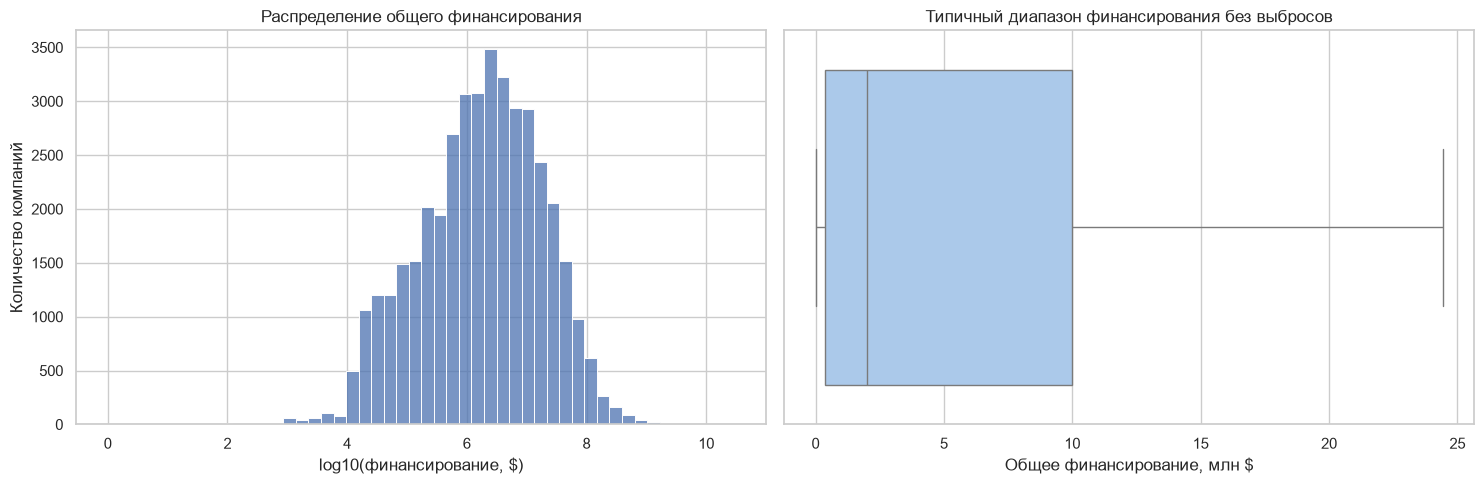

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    np.log10(investments['funding_total_usd']),
    bins=50,
    ax=axes[0],
    color='#4C72B0'
)
axes[0].set_title('Распределение общего финансирования')
axes[0].set_xlabel('log10(финансирование, $)')
axes[0].set_ylabel('Количество компаний')

sns.boxplot(
    x=investments['funding_total_usd'] / 1e6,
    showfliers=False,
    ax=axes[1],
    color='#A1C9F4'
)
axes[1].set_title('Типичный диапазон финансирования без выбросов')
axes[1].set_xlabel('Общее финансирование, млн $')

plt.tight_layout()
plt.show()

In [19]:
global_q1 = investments['funding_total_usd'].quantile(0.25)
global_q3 = investments['funding_total_usd'].quantile(0.75)
global_iqr_upper = global_q3 + 1.5 * (global_q3 - global_q1)

print(f'Q1: {global_q1 / 1e6:.2f} млн $')
print(f'Медиана: {investments["funding_total_usd"].median() / 1e6:.2f} млн $')
print(f'Q3: {global_q3 / 1e6:.2f} млн $')
print(f'Глобальная верхняя граница IQR: {global_iqr_upper / 1e6:.2f} млн $')

Q1: 0.35 млн $
Медиана: 2.00 млн $
Q3: 10.00 млн $
Глобальная верхняя граница IQR: 24.48 млн $


Распределение сильно скошено вправо. Центральные 50% компаний получили от 0,35 до 10 млн долларов, медиана равна 2 млн. Если применять IQR ко всей выборке, верхняя граница составит около 24,48 млн долларов. Однако рынки заметно различаются по масштабу, поэтому окончательные границы нужно рассчитывать отдельно внутри каждого сегмента.

In [20]:
segment_iqr = (
    investments.groupby('market')['funding_total_usd']
      .quantile([0.25, 0.75])
      .unstack()
)
segment_iqr.columns = ['q1', 'q3']
segment_iqr['iqr'] = segment_iqr['q3'] - segment_iqr['q1']
segment_iqr['lower_bound'] = (
    segment_iqr['q1'] - 1.5 * segment_iqr['iqr']
).clip(lower=0)
segment_iqr['upper_bound'] = (
    segment_iqr['q3'] + 1.5 * segment_iqr['iqr']
)

investments = investments.join(
    segment_iqr[['lower_bound', 'upper_bound']], on='market'
)
investments['is_funding_outlier'] = (
    investments['funding_total_usd'].lt(investments['lower_bound'])
    | investments['funding_total_usd'].gt(investments['upper_bound'])
)

outlier_share = (
    investments.groupby('market')['is_funding_outlier']
      .agg(outliers='sum', companies='size', share='mean')
      .assign(share_pct=lambda x: x['share'] * 100)
      .sort_values('share_pct', ascending=False)
)

print(f'Аномальных компаний: {investments["is_funding_outlier"].sum():,} '
      f'({investments["is_funding_outlier"].mean():.1%})')
outlier_share.head(15).round(2)

Аномальных компаний: 5,244 (12.8%)


,outliers,companies,share,share_pct
market,,,,
Real Estate,48,279,0.17,17.20
Entertainment,25,150,0.17,16.67
Consulting,58,349,0.17,16.62
Search,48,291,0.16,16.49
Cloud Computing,25,152,0.16,16.45
Photography,33,204,0.16,16.18
SaaS,44,272,0.16,16.18
Technology,38,238,0.16,15.97
Video,30,188,0.16,15.96


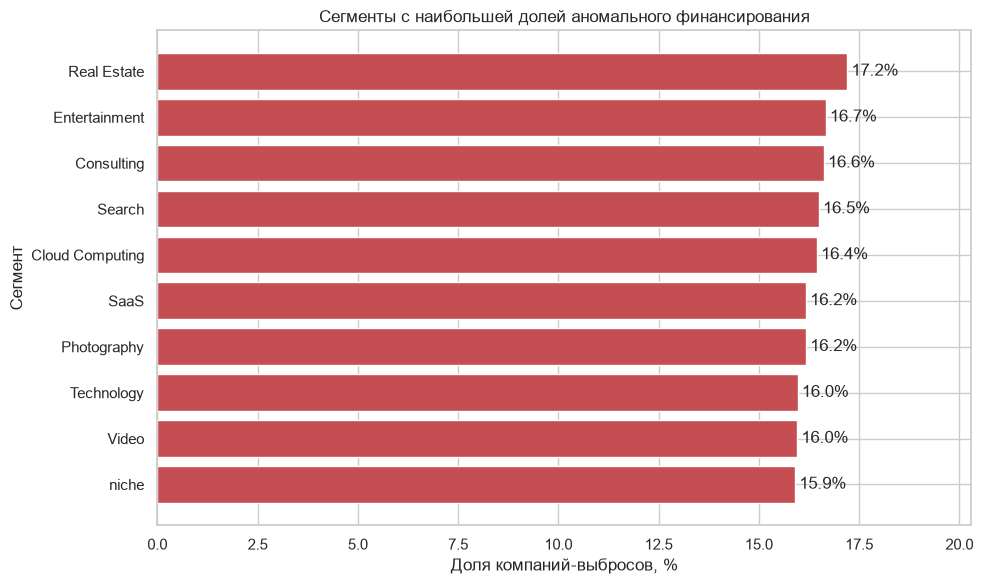

In [21]:
top_outlier_segments = outlier_share.head(10).sort_values('share_pct')

plt.figure(figsize=(10, 6))
bars = plt.barh(
    top_outlier_segments.index,
    top_outlier_segments['share_pct'],
    color='#C44E52'
)
plt.bar_label(bars, fmt='%.1f%%', padding=3)
plt.title('Сегменты с наибольшей долей аномального финансирования')
plt.xlabel('Доля компаний-выбросов, %')
plt.ylabel('Сегмент')
plt.xlim(0, top_outlier_segments['share_pct'].max() * 1.18)
plt.tight_layout()
plt.show()

Сегментный IQR выявил 5 244 компании с аномальным финансированием — 12,8% выборки. Наибольшая доля выбросов у `Real Estate` (17,2%), `Entertainment` (16,7%) и `Consulting` (16,6%). Высокая доля не означает ошибку: в этих рынках могут сосуществовать небольшие стартапы и капиталоёмкие проекты. Для анализа типичной динамики выбросы будут исключены, но исходная таблица сохранена отдельно.

### 3.2 Полнота 2014 года и границы периода

Проверю количество компаний, раундов и суммарное финансирование по средней дате финансирования до удаления выбросов.

,companies,rounds,funding_usd
year,,,
2000,103,247.00,2760570945
2001,63,163.00,1676288435
2002,70,164.00,2553437335
2003,90,260.00,2251138825
2004,150,410.00,4236114902
2005,843,"1,446.00",16960252268
2006,1463,"2,914.00",29818099913
2007,2107,"4,845.00",52390476688
2008,2588,"6,024.00",72041478744


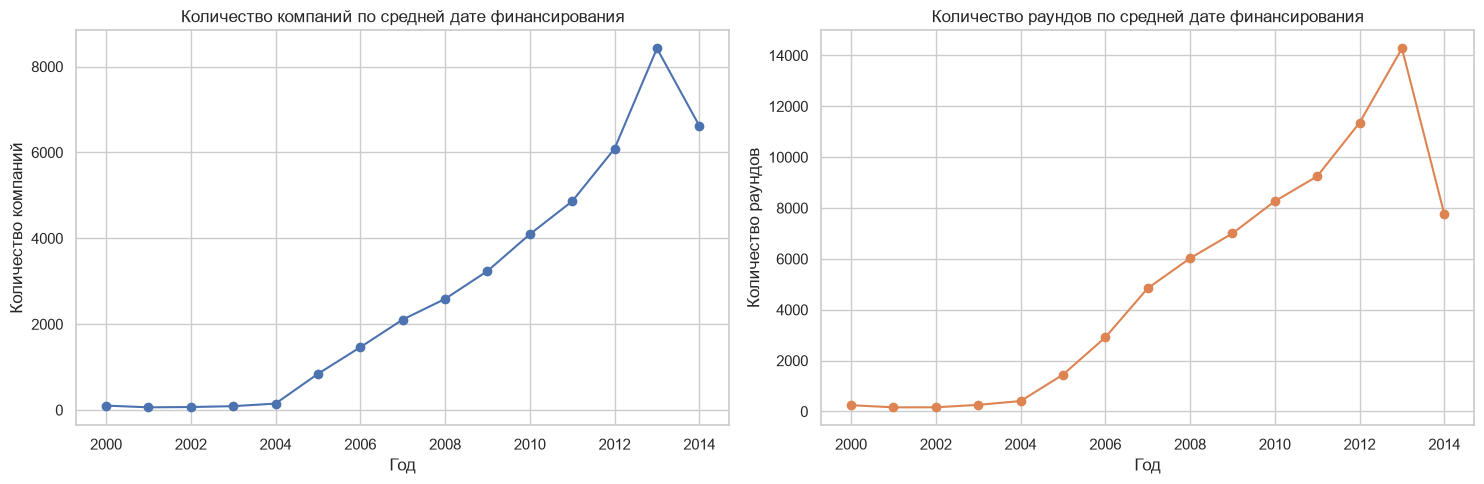

In [22]:
yearly_source = (
    investments.assign(year=investments['mid_funding_at'].dt.year)
      .groupby('year')
      .agg(
          companies=('name', 'size'),
          rounds=('funding_rounds', 'sum'),
          funding_usd=('funding_total_usd', 'sum')
      )
)

display(yearly_source.loc[2000:2014])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
yearly_source.loc[2000:2014, 'companies'].plot(
    ax=axes[0], marker='o', color='#4C72B0'
)
axes[0].set_title('Количество компаний по средней дате финансирования')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Количество компаний')

yearly_source.loc[2000:2014, 'rounds'].plot(
    ax=axes[1], marker='o', color='#DD8452'
)
axes[1].set_title('Количество раундов по средней дате финансирования')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Количество раундов')

plt.tight_layout()
plt.show()

In [23]:
companies_change_2014 = (
    yearly_source.loc[2014, 'companies']
    / yearly_source.loc[2013, 'companies'] - 1
)
rounds_change_2014 = (
    yearly_source.loc[2014, 'rounds']
    / yearly_source.loc[2013, 'rounds'] - 1
)

print(f'Изменение числа компаний в 2014 к 2013: {companies_change_2014:.1%}')
print(f'Изменение числа раундов в 2014 к 2013: {rounds_change_2014:.1%}')

Изменение числа компаний в 2014 к 2013: -21.4%
Изменение числа раундов в 2014 к 2013: -45.7%


В 2014 году число компаний снизилось на 21,4%, а число раундов — на 45,7% относительно 2013 года. Такое резкое синхронное падение после многолетнего роста указывает, что данные за 2014 год, вероятнее всего, неполные. Год оставлю в анализе, поскольку это требуется заданием, но не буду интерпретировать снижение как достоверное ухудшение рынка.

In [24]:
filtered_investments = investments.loc[
    ~investments['is_funding_outlier']
].copy()
filtered_investments['year'] = filtered_investments['mid_funding_at'].dt.year

rounds_by_year = (
    filtered_investments.groupby('year')['funding_rounds']
      .sum()
      .sort_index()
)
valid_years = rounds_by_year[rounds_by_year >= 50].index

analysis_df = filtered_investments.loc[
    filtered_investments['year'].isin(valid_years)
].copy()

print(f'После удаления выбросов: {len(filtered_investments):,} компаний')
print(f'После фильтра по годам: {len(analysis_df):,} компаний')
print(f'Период анализа: {valid_years.min()}–{valid_years.max()} годы')

rounds_by_year.loc[valid_years].to_frame('funding_rounds')

После удаления выбросов: 35,663 компаний
После фильтра по годам: 35,588 компаний
Период анализа: 2000–2014 годы


,funding_rounds
year,
2000,113.00
2001,66.00
2002,98.00
2003,125.00
2004,181.00
2005,948.00
2006,"1,849.00"
2007,"2,842.00"
2008,"3,663.00"


После удаления сегментных выбросов осталось 35 661 компания. Условию не менее 50 раундов соответствуют годы с 2000 по 2014; итоговая аналитическая выборка содержит 35 587 компаний. Этот период совпадает с периодом таблицы возвратов и используется далее.

### 3.3 Типы финансирования по объёму и популярности

In [25]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]

type_stats = pd.DataFrame({
    'amount_usd': analysis_df[funding_types].sum(),
    'companies': analysis_df[funding_types].gt(0).sum()
})
type_stats['amount_bln_usd'] = type_stats['amount_usd'] / 1e9
type_stats['avg_mln_usd'] = (
    type_stats['amount_usd'] / type_stats['companies'] / 1e6
)
type_stats.sort_values('amount_usd', ascending=False).round(3)

,amount_usd,companies,amount_bln_usd,avg_mln_usd
venture,"129,092,208,088.00",18820,129.09,6.86
seed,"9,431,331,895.00",13375,9.43,0.70
debt_financing,"8,178,152,734.00",3265,8.18,2.50
private_equity,"4,843,108,504.00",634,4.84,7.64
angel,"2,481,263,836.00",2937,2.48,0.84
undisclosed,"2,100,352,252.00",813,2.10,2.58
grant,"1,978,848,688.00",1003,1.98,1.97
post_ipo_equity,"1,946,452,068.00",164,1.95,11.87
convertible_note,"566,039,436.00",521,0.57,1.09
post_ipo_debt,"286,718,349.00",27,0.29,10.62


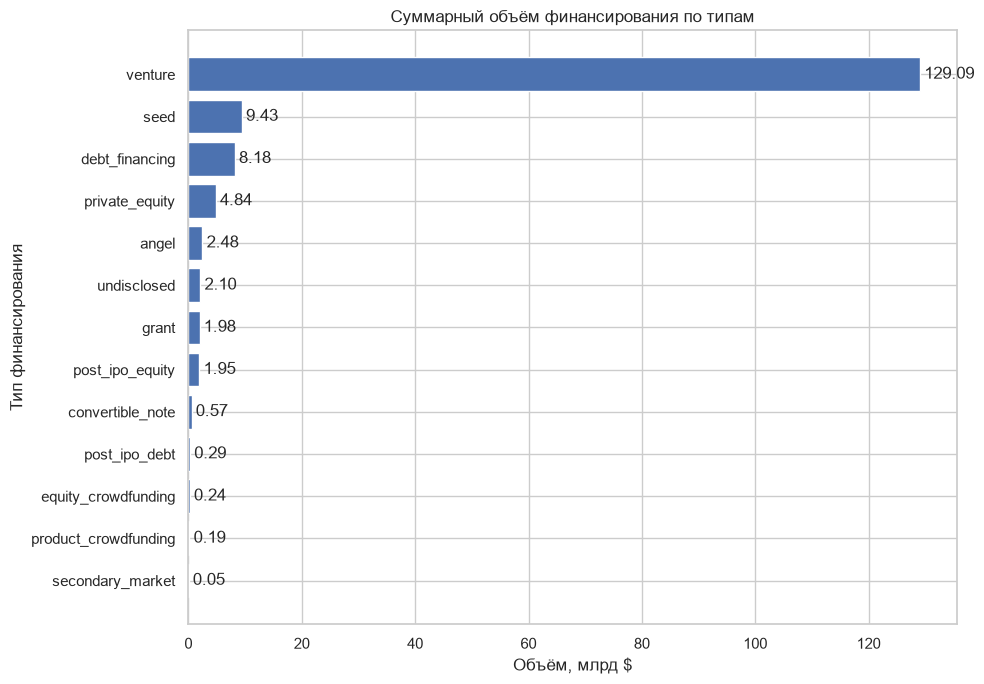

In [26]:
amount_order = type_stats['amount_bln_usd'].sort_values()

plt.figure(figsize=(10, 7))
bars = plt.barh(amount_order.index, amount_order, color='#4C72B0')
plt.bar_label(bars, fmt='%.2f', padding=3)
plt.title('Суммарный объём финансирования по типам')
plt.xlabel('Объём, млрд $')
plt.ylabel('Тип финансирования')
plt.tight_layout()
plt.show()

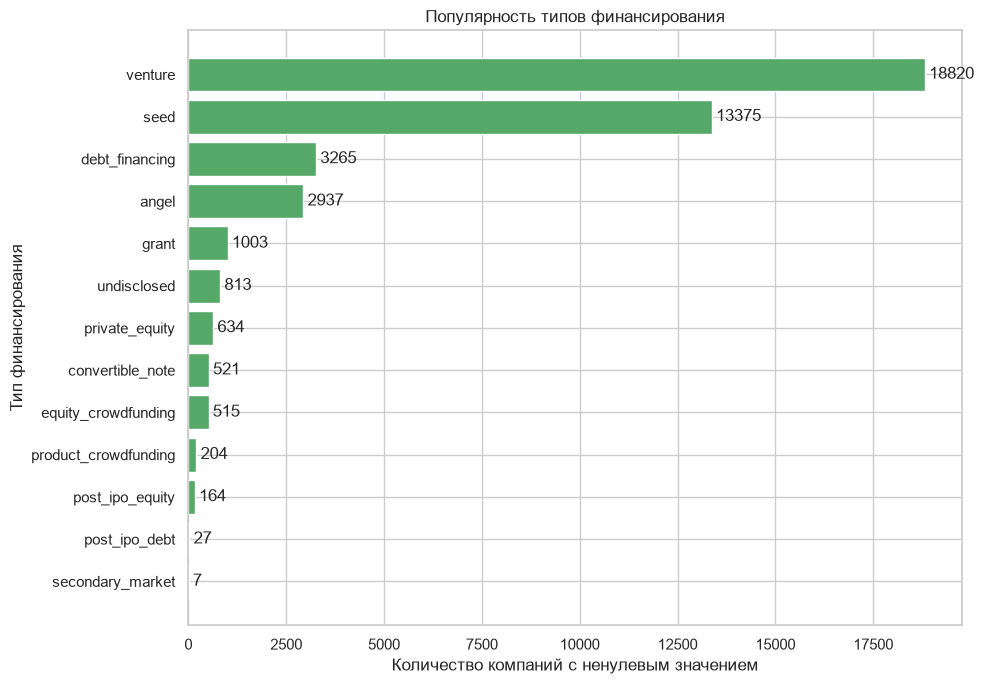

In [27]:
company_order = type_stats['companies'].sort_values()

plt.figure(figsize=(10, 7))
bars = plt.barh(company_order.index, company_order, color='#55A868')
plt.bar_label(bars, fmt='%d', padding=3)
plt.title('Популярность типов финансирования')
plt.xlabel('Количество компаний с ненулевым значением')
plt.ylabel('Тип финансирования')
plt.tight_layout()
plt.show()

`Venture` лидирует и по объёму (129,1 млрд долларов), и по популярности (18 820 компаний). `Seed` встречается почти так же часто — у 13 375 компаний, — но даёт лишь 9,43 млрд: средняя сумма около 0,71 млн долларов. Аналогично часто используемые `angel` и краудфандинг характеризуются небольшими суммами.

Обратная ситуация у `private_equity`, `post_ipo_equity` и `post_ipo_debt`: они встречаются редко, но средний объём на компанию высок — примерно 7,6, 11,9 и 10,6 млн долларов соответственно.

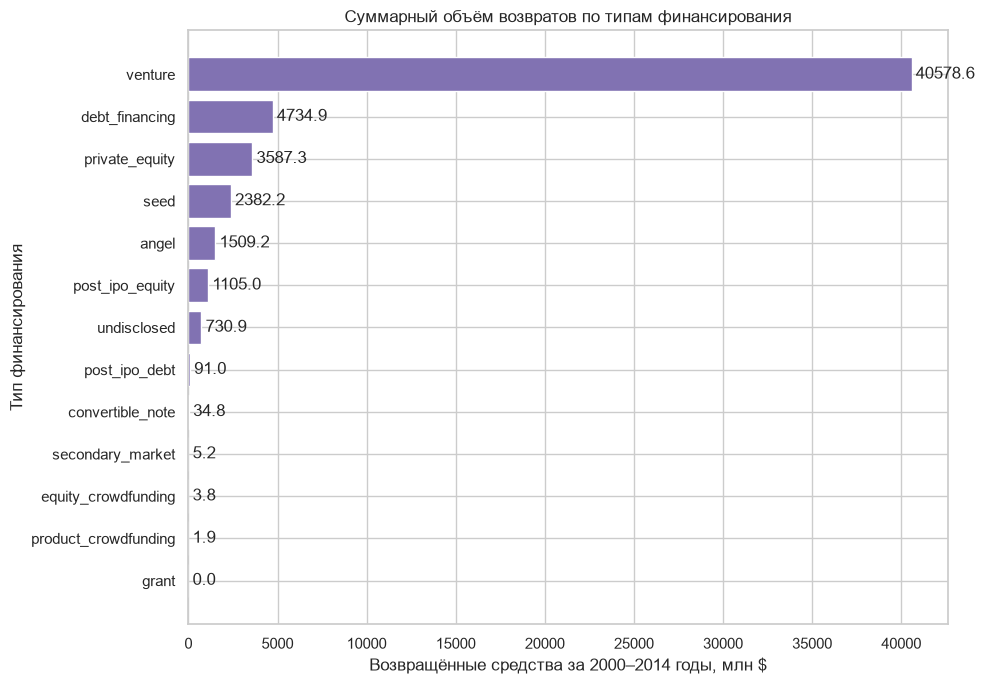

In [28]:
returns_total = returns[funding_types].sum().sort_values()

plt.figure(figsize=(10, 7))
bars = plt.barh(returns_total.index, returns_total, color='#8172B2')
plt.bar_label(bars, fmt='%.1f', padding=3)
plt.title('Суммарный объём возвратов по типам финансирования')
plt.xlabel('Возвращённые средства за 2000–2014 годы, млн $')
plt.ylabel('Тип финансирования')
plt.tight_layout()
plt.show()

По абсолютному объёму возвратов также лидирует `venture` — около 40,6 млрд долларов за период. Далее идут `debt_financing` (4,73 млрд), `private_equity` (3,59 млрд), `seed` (2,38 млрд) и `angel` (1,51 млрд). Абсолютные суммы подтверждают масштаб венчурного рынка, но не показывают эффективность на единицу вложенных средств — для этого в шаге 4.3 будет рассчитан нормированный показатель.

### Промежуточный вывод по шагу 3

Типичный общий объём финансирования находится в интервале 0,35–10 млн долларов. После расчёта IQR внутри каждого сегмента 12,8% компаний отмечены как выбросы и исключены из динамического анализа. Надёжный по числу раундов период — 2000–2014 годы, но 2014 год неполон.

Венчурное финансирование доминирует по объёму, распространённости и абсолютным возвратам. `Seed` и `angel` популярны, но дают небольшие суммы; `private_equity` и пост-IPO-инструменты используются реже, зато предполагают крупный чек.

---

## Шаг 4. Анализ динамики

### 4.1 Типичный размер раунда и рыночная активность

Для каждой компании рассчитаю средний объём одного раунда, затем по годам найду медиану этого показателя и суммарное количество раундов.

In [29]:
analysis_df['avg_round_usd'] = (
    analysis_df['funding_total_usd'] / analysis_df['funding_rounds']
)

yearly_dynamics = (
    analysis_df.groupby('year')
      .agg(
          median_round_usd=('avg_round_usd', 'median'),
          funding_rounds=('funding_rounds', 'sum'),
          companies=('name', 'size')
      )
)
yearly_dynamics

,median_round_usd,funding_rounds,companies
year,,,
2000,"2,250,000.00",113.00,65
2001,"1,570,886.00",66.00,37
2002,"3,225,000.00",98.00,48
2003,"1,500,000.00",125.00,63
2004,"3,000,000.00",181.00,96
2005,"4,500,000.00",948.00,697
2006,"3,900,000.00","1,849.00",1165
2007,"2,879,166.67","2,842.00",1600
2008,"2,170,743.75","3,663.00",1984


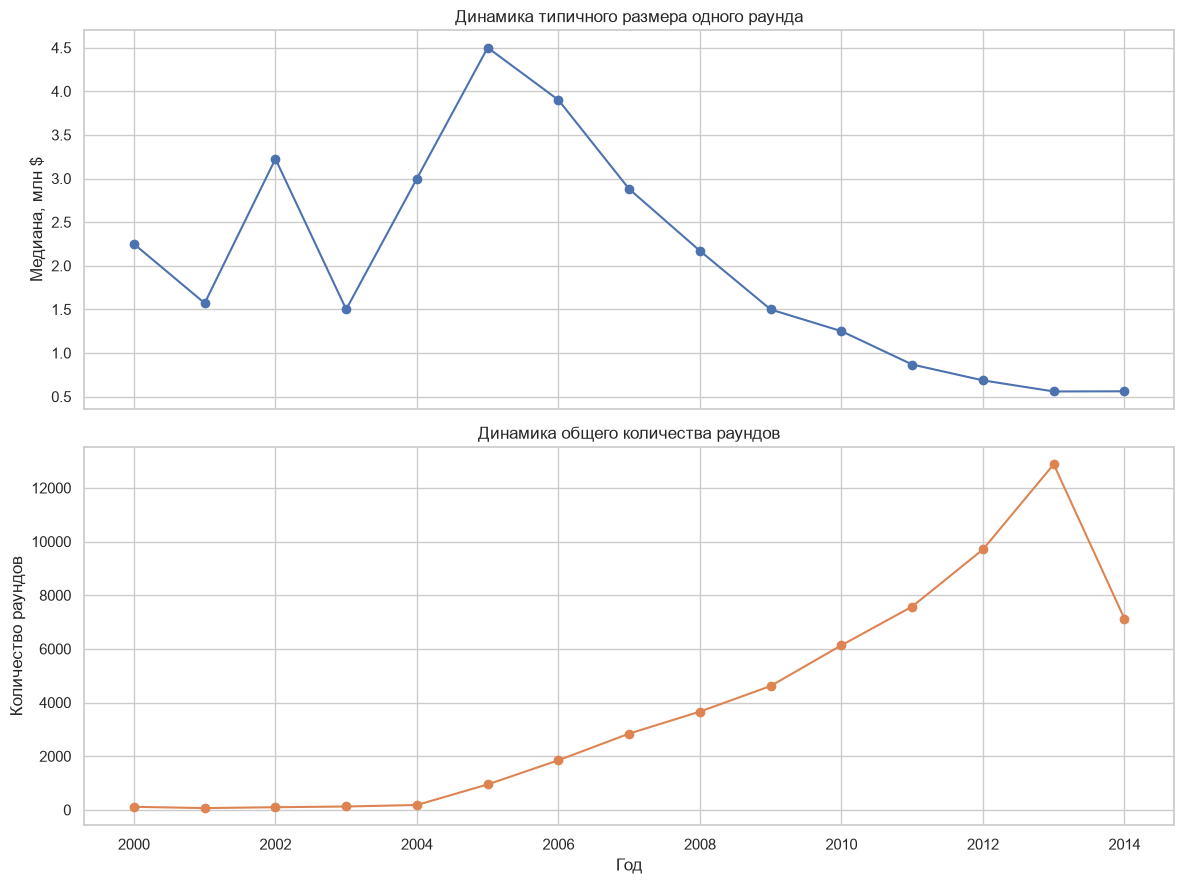

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

(yearly_dynamics['median_round_usd'] / 1e6).plot(
    ax=axes[0], marker='o', color='#4C72B0'
)
axes[0].set_title('Динамика типичного размера одного раунда')
axes[0].set_ylabel('Медиана, млн $')
axes[0].set_xlabel('')

yearly_dynamics['funding_rounds'].plot(
    ax=axes[1], marker='o', color='#DD8452'
)
axes[1].set_title('Динамика общего количества раундов')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Количество раундов')

plt.tight_layout()
plt.show()

In [31]:
max_round_year = yearly_dynamics['median_round_usd'].idxmax()
max_round_value = yearly_dynamics.loc[max_round_year, 'median_round_usd']
rounds_change_filtered_2014 = (
    yearly_dynamics.loc[2014, 'funding_rounds']
    / yearly_dynamics.loc[2013, 'funding_rounds'] - 1
)
median_change_2014 = (
    yearly_dynamics.loc[2014, 'median_round_usd']
    / yearly_dynamics.loc[2013, 'median_round_usd'] - 1
)

print(f'Максимальная медиана раунда: {max_round_year} год, '
      f'{max_round_value / 1e6:.2f} млн $')
print(f'Изменение числа раундов в 2014: {rounds_change_filtered_2014:.1%}')
print(f'Изменение медианы раунда в 2014: {median_change_2014:.1%}')

Максимальная медиана раунда: 2005 год, 4.50 млн $
Изменение числа раундов в 2014: -44.7%
Изменение медианы раунда в 2014: 0.3%


Максимальный типичный размер одного раунда наблюдался в 2005 году = 4,5 млн долларов. После этого медиана в целом снижалась и к 2013 и 2014 годам составляла около 0,56 млн долларов, одновременно число раундов быстро росло. Это похоже на расширение рынка за счёт большего числа небольших сделок.

В 2014 году медиана почти не изменилась (+0,3%), а количество раундов снизилось на 44,7%. С учётом выявленной неполноты данных это падение нельзя считать реальной рыночной тенденцией.

### 4.2 Растущие в 2014 году массовые сегменты

Оставлю только массовые рынки и выберу те, у которых суммарное финансирование в 2014 году превышает уровень 2013 года.

In [32]:
mass_markets = market_class[market_class.eq('mass')].index

market_year_pivot = (
    analysis_df.loc[analysis_df['market'].isin(mass_markets)]
      .pivot_table(
          index='year',
          columns='market',
          values='funding_total_usd',
          aggfunc='sum',
          fill_value=0
      )
)

growing_markets = market_year_pivot.columns[
    market_year_pivot.loc[2014] > market_year_pivot.loc[2013]
]

growth_2014 = pd.DataFrame({
    '2013_mln_usd': market_year_pivot.loc[2013, growing_markets] / 1e6,
    '2014_mln_usd': market_year_pivot.loc[2014, growing_markets] / 1e6
})
growth_2014['growth_pct'] = (
    growth_2014['2014_mln_usd']
    / growth_2014['2013_mln_usd'] - 1
) * 100
growth_2014.sort_values('growth_pct', ascending=False).round(1)

,2013_mln_usd,2014_mln_usd,growth_pct
market,,,
Medical,64.50,175.20,171.80
Startups,18.10,41.50,129.50
Apps,28.90,66.20,129.40
Internet,69.70,117.80,69.00
Technology,120.90,202.00,67.10
Real Estate,92.20,115.60,25.30
SaaS,79.60,92.80,16.60
Design,61.00,69.00,13.20
Manufacturing,393.90,416.30,5.70


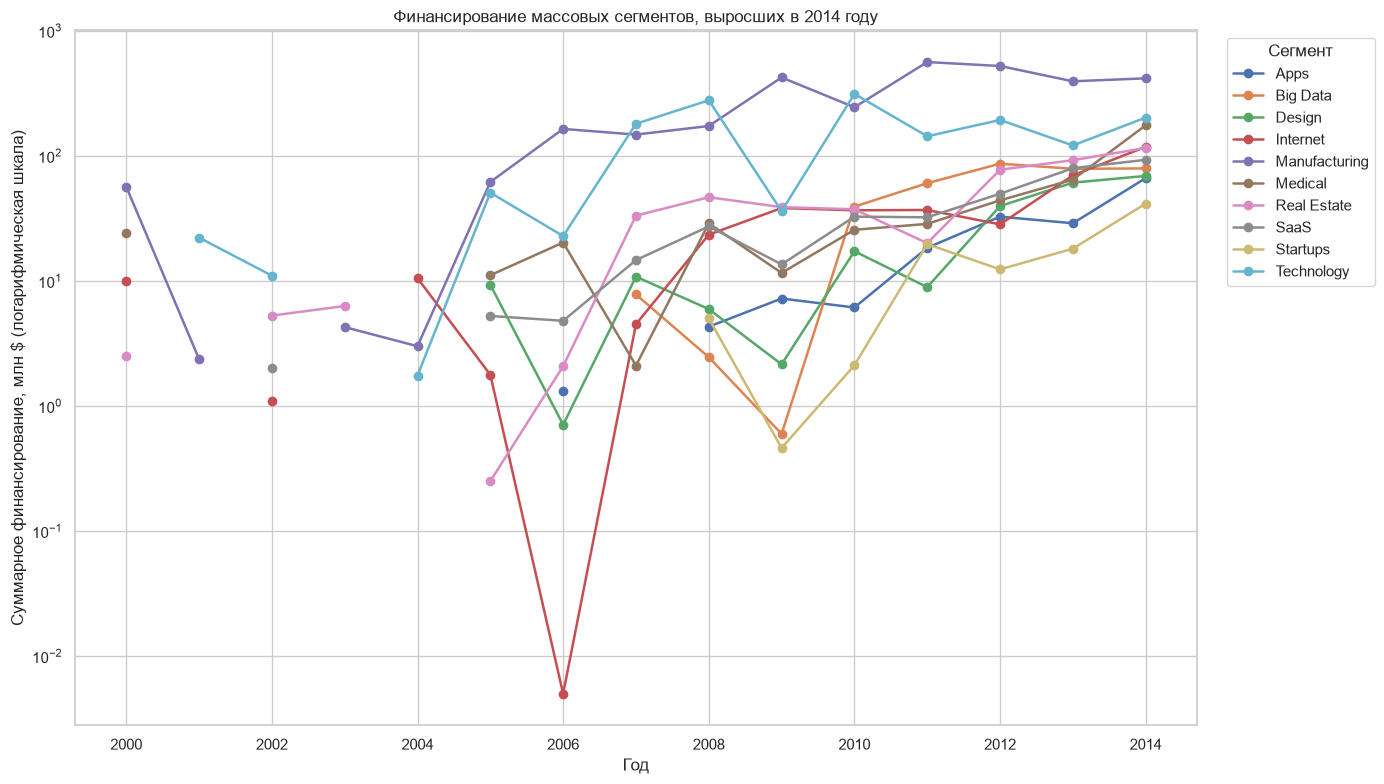

In [33]:
plot_data = market_year_pivot[growing_markets].replace(0, np.nan) / 1e6

plt.figure(figsize=(14, 8))
for market in growing_markets:
    plt.plot(
        plot_data.index,
        plot_data[market],
        marker='o',
        linewidth=1.8,
        label=market
    )

plt.yscale('log')
plt.title('Финансирование массовых сегментов, выросших в 2014 году')
plt.xlabel('Год')
plt.ylabel('Суммарное финансирование, млн $ (логарифмическая шкала)')
plt.legend(title='Сегмент', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [34]:
recent_growth_metrics = []
for market in growing_markets:
    series = market_year_pivot.loc[2009:2014, market]
    positive_years = int(series.diff().dropna().gt(0).sum())
    cagr = (
        (series.iloc[-1] / series.iloc[0]) ** (1 / 5) - 1
        if series.iloc[0] > 0 else np.nan
    )
    recent_growth_metrics.append({
        'market': market,
        'positive_years_2009_2014': positive_years,
        'cagr_pct_2009_2014': cagr * 100,
        'growth_pct_2014': growth_2014.loc[market, 'growth_pct']
    })

recent_growth_metrics = (
    pd.DataFrame(recent_growth_metrics)
      .set_index('market')
      .sort_values('growth_pct_2014', ascending=False)
)
recent_growth_metrics.round(1)

,positive_years_2009_2014,cagr_pct_2009_2014,growth_pct_2014
market,,,
Medical,5,72.20,171.80
Startups,4,146.00,129.50
Apps,3,55.80,129.40
Internet,3,25.30,69.00
Technology,3,41.10,67.10
Real Estate,3,24.40,25.30
SaaS,4,47.00,16.60
Design,4,100.10,13.20
Manufacturing,2,-0.30,5.70


В 2014 году относительно 2013 выросли десять массовых сегментов. Самый убедительный результат у `Medical`: финансирование увеличилось со 64,5 до 175,2 млн долларов (+171,8%), причём рост наблюдался во все пять годовых интервалов с 2009 по 2014. `Startups` и `Apps` также выросли более чем вдвое, но их траектории были более волатильными. `SaaS` и `Design` показывали более умеренный, но сравнительно устойчивый рост.

Поскольку данные за 2014 год неполны, рост отдельных сегментов особенно примечателен, но точные проценты следует считать нижней оценкой объёма и не переносить напрямую на весь рынок.

### 4.3 Динамика нормированной доли возвратов

Для каждого года разделю возвращённые средства на предоставленные по соответствующему типу. Значения `cb_returns` переведу из миллионов в доллары. Как рекомендовано в задании, добавлю к знаменателю `1e-60`. Слишком большие значения заменю на пропуски по верхней границе IQR отдельно для каждого типа.

In [35]:
funding_by_year = (
    analysis_df.groupby('year')[funding_types]
      .sum()
      .sort_index()
)
returns_usd = returns[funding_types] * 1e6

common_years = funding_by_year.index.intersection(returns_usd.index)
return_ratio = (
    returns_usd.loc[common_years]
    / (funding_by_year.loc[common_years] + 1e-60)
)

return_outliers_removed = {}
for column in return_ratio.columns:
    q1 = return_ratio[column].quantile(0.25)
    q3 = return_ratio[column].quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    anomaly_mask = return_ratio[column].gt(upper)
    return_outliers_removed[column] = int(anomaly_mask.sum())
    return_ratio.loc[anomaly_mask, column] = np.nan

selected_return_types = [
    'venture', 'debt_financing', 'private_equity', 'seed', 'angel'
]
return_ratio[selected_return_types].round(3)

,venture,debt_financing,private_equity,seed,angel
year,,,,,
2000,0.17,0.62,0.00,1.00,0.27
2001,0.11,0.77,0.00,1.08,1.18
2002,0.68,0.22,0.20,0.63,1.14
2003,0.63,1.04,NaN,0.51,0.61
2004,0.84,0.44,NaN,0.55,0.83
2005,0.55,0.34,0.48,0.68,0.51
2006,0.34,0.80,0.94,0.93,0.68
2007,0.30,0.60,0.58,0.37,0.82
2008,0.19,0.93,0.68,0.30,0.41


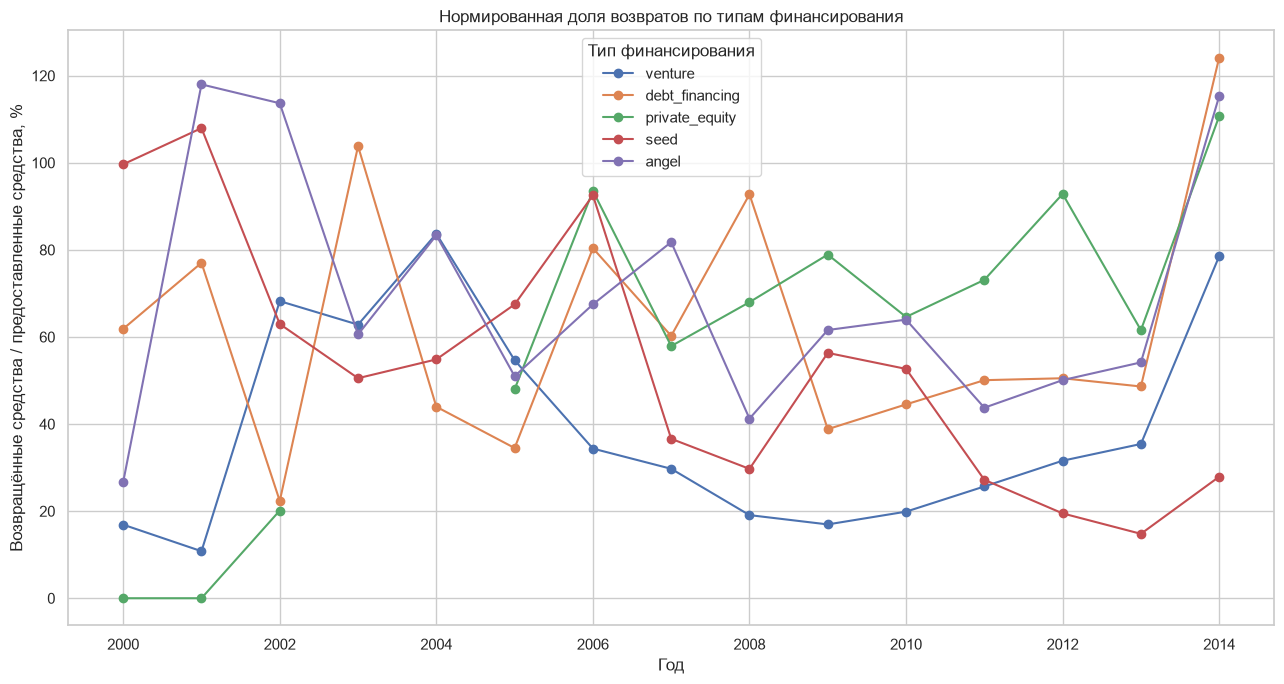

In [36]:
plt.figure(figsize=(13, 7))
for funding_type in selected_return_types:
    plt.plot(
        return_ratio.index,
        return_ratio[funding_type] * 100,
        marker='o',
        label=funding_type
    )

plt.title('Нормированная доля возвратов по типам финансирования')
plt.xlabel('Год')
plt.ylabel('Возвращённые средства / предоставленные средства, %')
plt.legend(title='Тип финансирования')
plt.tight_layout()
plt.show()

In [37]:
trend_rows = []
for funding_type in selected_return_types:
    series = return_ratio[funding_type].dropna()
    years_as_series = pd.Series(
        series.index.astype(float), index=series.index
    )
    trend_rows.append({
        'funding_type': funding_type,
        'years_available': len(series),
        'first_ratio': series.iloc[0],
        'last_ratio': series.iloc[-1],
        'spearman_with_year': series.corr(
            years_as_series, method='spearman'
        )
    })

return_trends = (
    pd.DataFrame(trend_rows)
      .set_index('funding_type')
      .sort_values('spearman_with_year', ascending=False)
)
return_trends.round(3)

,years_available,first_ratio,last_ratio,spearman_with_year
funding_type,,,,
private_equity,13,0.00,1.11,0.73
venture,15,0.17,0.79,0.14
debt_financing,15,0.62,1.24,0.06
angel,15,0.27,1.15,-0.12
seed,15,1.00,0.28,-0.82


Наиболее устойчивый рост нормированного показателя наблюдается у `private_equity`: ранговая корреляция с годом составляет около 0,77. У `venture` после минимума 2008–2009 годов показатель постепенно восстанавливался, но долгосрочный тренд слабее. `Seed` демонстрирует выраженное снижение, а `angel` и `debt_financing` сильно колеблются.

Значения выше 100% не следует трактовать как буквальную доходность конкретной когорты: таблица возвратов не связывает возврат с теми же компаниями и раундами, которые формируют годовой знаменатель. Кроме того, неполный объём финансирования за 2014 год искусственно повышает нормированный показатель последнего года.

### Промежуточный вывод по шагу 4

- Максимальный типичный размер раунда был в 2005 году = 4,5 млн долларов. Затем медиана снижалась на фоне роста числа раундов.
- В 2014 году число зафиксированных раундов резко упало, но это связано прежде всего с неполнотой данных.
- Среди массовых рынков наиболее быстрый и последовательный рост показал `Medical`.
- По нормированной динамике возвратов наиболее устойчивый рост наблюдался у `private_equity`; венчурное финансирование лидирует по абсолютному масштабу, но его относительный показатель менее стабилен.

---

## Шаг 5. Итоговый вывод и рекомендации

### 1. Общий обзор работы

Я загрузила данные о 54 294 компаниях и возвратах за 2000–2014 годы, привела названия и типы данных к корректному виду, обработала дубликаты и пропуски и восстановила среднюю дату финансирования. После предобработки осталось 40 905 компаний. Затем я сформировала группы по срокам финансирования, объединила небольшие рынки, рассчитала сегментные границы выбросов и выделила аналитический период с достаточным числом раундов.

Для очищенной выборки я сравнила типы финансирования по объёму, распространённости и возвратам, изучила динамику типичного раунда и активности рынка, нашла растущие массовые сегменты и рассчитала нормированную долю возвратов.

### 2. Главные результаты

- 59% компаний имели один раунд, но 61,9% всех средств получили компании, которые привлекали финансирование более года.
- Центральные 50% компаний привлекли от 0,35 до 10 млн долларов; 12,8% наблюдений признаны сегментными выбросами по IQR.
- Надёжный по числу раундов период — 2000–2014 годы, однако данные за 2014 год неполны.
- `Venture` доминирует по объёму, популярности и абсолютным возвратам. `Seed` используется часто, но имеет небольшой средний чек; `private_equity` используется реже, зато характеризуется крупными суммами.
- Среди массовых рынков `Medical` показал наиболее быстрый и последовательный рост: финансирование росло каждый год с 2009 по 2014, а в 2014 увеличилось примерно на 172%.
- Наиболее устойчивый рост нормированной доли возвратов наблюдался у `private_equity`. У `seed` показатель, напротив, снижался.

### 3. Рекомендация заказчику на 2015 год

**Основная рекомендация: рассмотреть компании сегмента `Medical` и использовать `private_equity` как основной тип финансирования.**

Сегмент `Medical` относится к массовым и сочетает высокий темп с устойчивостью роста. `Private equity` соответствует стратегии покупки, развития и последующей перепродажи компаний: инструмент применяется реже венчурного финансирования, но предполагает более крупный средний объём и показывает наиболее устойчивый рост нормированного возврата.

Для более широкого портфеля можно использовать `venture` как дополнительный инструмент: он обеспечивает максимальный выбор компаний и крупнейший абсолютный объём возвратов, но его относительная динамика менее стабильна.

### 4. Ограничения

Рекомендацию следует проверить на данных о прибыльности, оценке компаний, сроках выхода и фактических сделках. Данные за 2014 год неполны; у 2 503 компаний неизвестен рынок; выбросы исключены из динамики; а возвраты не связаны с конкретными когортами профинансированных компаний. Поэтому анализ показывает направление для углублённой проверки, а не готовое инвестиционное решение.